<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train shape: (3000, 784) | Test shape: (500, 784)

=== Task 3: Training RBMs (CD-1, CD-5, CD-10, PCD-1) ===
CD-1   | Time:  7.57s | Final Recon MSE: 0.0481 | Final Test PLL: -128.60
CD-5   | Time: 16.89s | Final Recon MSE: 0.0489 | Final Test PLL: -135.40
CD-10  | Time: 25.04s | Final Recon MSE: 0.0491 | Final Test PLL: -134.41
PCD-1  | Time:  6.63s | Final Recon MSE: 0.0562 | Final Test PLL: -136.16


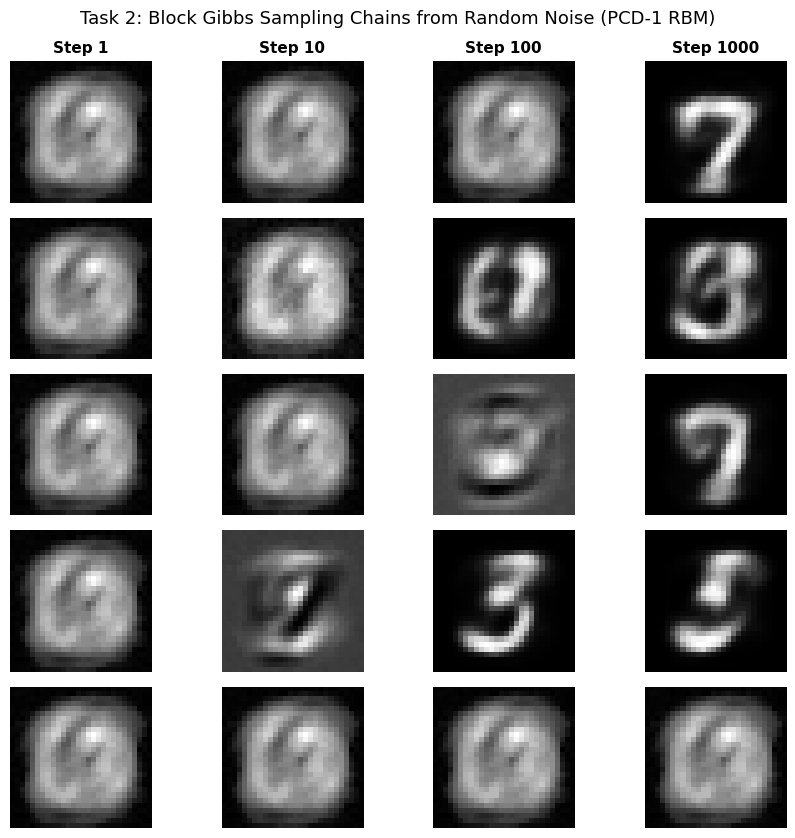

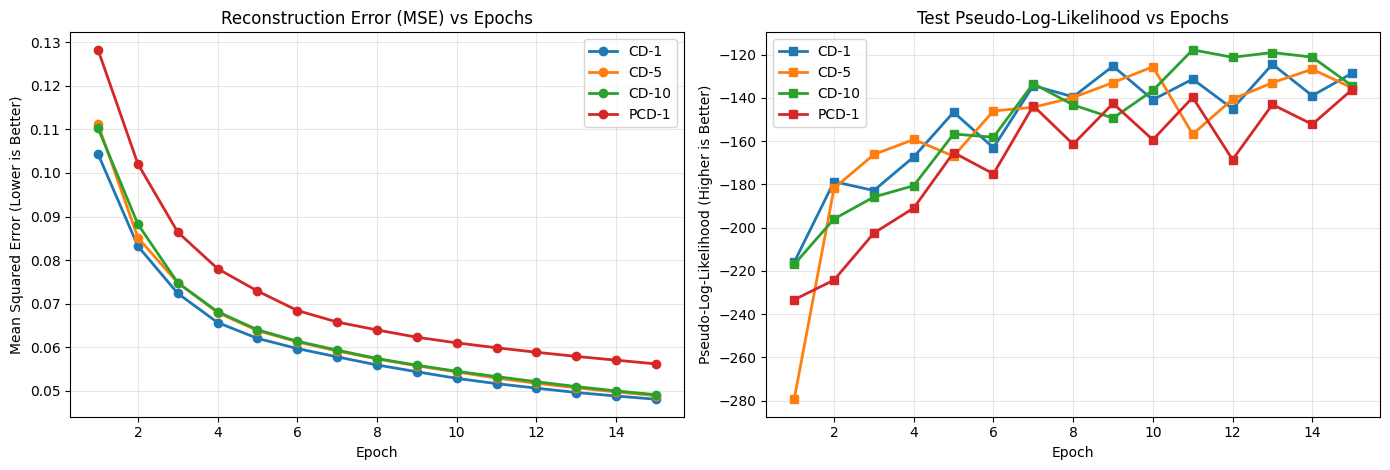


=== Task 5: Training Time vs Quantitative Metrics ===
Method  Train Time (s)  Final Recon MSE  Final Test PLL
  CD-1            7.57           0.0481         -128.60
  CD-5           16.89           0.0489         -135.40
 CD-10           25.04           0.0491         -134.41
 PCD-1            6.63           0.0562         -136.16


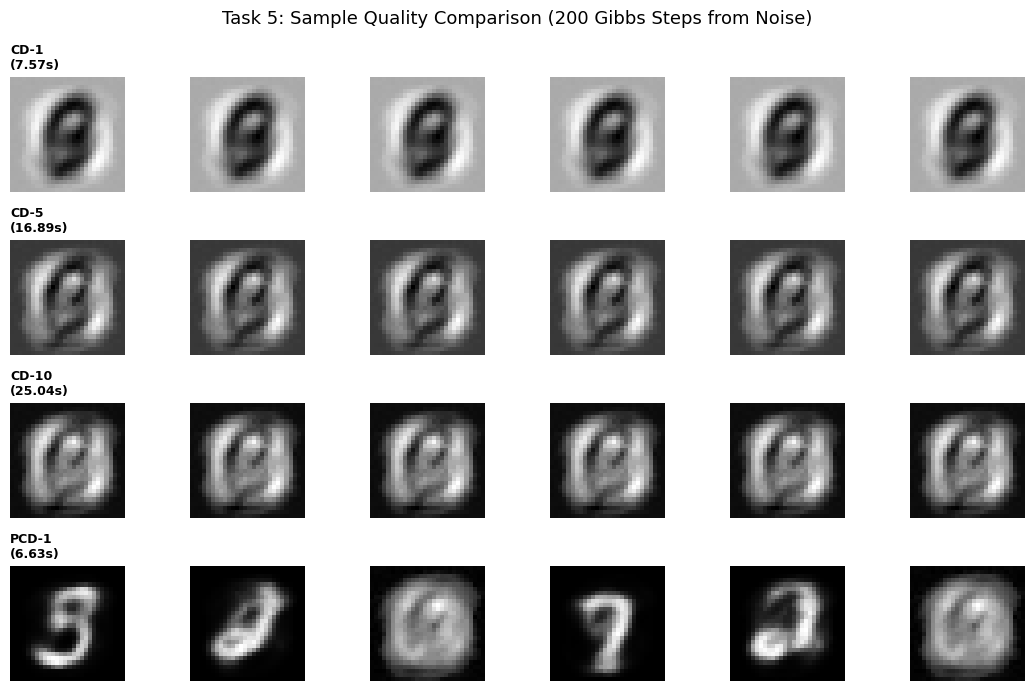

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit as sigmoid
from tensorflow.keras.datasets import mnist

# Reproducibility
np.random.seed(42)

# ==========================================
# Load & Binarise MNIST Dataset (784 Visible Units)
# ==========================================
(X_train_raw, _), (X_test_raw, _) = mnist.load_data()

# Subset sized so CD-1, CD-5, CD-10, and PCD finish quickly in Colab
X_train = (X_train_raw[:3000].reshape(-1, 784) / 255.0 > 0.5).astype(np.float32)
X_test  = (X_test_raw[:500].reshape(-1, 784) / 255.0 > 0.5).astype(np.float32)

print(f"Train shape: {X_train.shape} | Test shape: {X_test.shape}\n")

# ==========================================
# Task 1 & 3: RBM with Block Gibbs Sampling, CD-k, and Persistent CD (PCD)
# ==========================================
class RBM:
    def __init__(self, n_visible=784, n_hidden=64, seed=42):
        self.n_visible = n_visible
        self.n_hidden = n_hidden
        rng = np.random.default_rng(seed)
        self.W = rng.normal(0.0, 0.01, size=(n_visible, n_hidden)).astype(np.float32)
        self.a = np.zeros(n_visible, dtype=np.float32)
        self.b = np.zeros(n_hidden, dtype=np.float32)

    def prob_h_given_v(self, v):
        return sigmoid(v @ self.W + self.b)

    def prob_v_given_h(self, h):
        return sigmoid(h @ self.W.T + self.a)

    def sample_bernoulli(self, probs):
        return (np.random.rand(*probs.shape) < probs).astype(np.float32)

    def free_energy(self, v):
        wx_b = v @ self.W + self.b
        return -(v @ self.a) - np.sum(np.logaddexp(0.0, wx_b), axis=1)

    # Task 1: One step of Block Gibbs Sampling (v -> h -> v)
    def gibbs_step(self, v):
        p_h = self.prob_h_given_v(v)
        h_sample = self.sample_bernoulli(p_h)
        p_v = self.prob_v_given_h(h_sample)
        v_sample = self.sample_bernoulli(p_v)
        return v_sample, p_v, h_sample, p_h

    # Run k steps of Block Gibbs Sampling
    def gibbs_chain(self, v_init, steps=1):
        v = v_init.copy()
        p_v = v_init.copy()
        for _ in range(steps):
            v, p_v, _, _ = self.gibbs_step(v)
        return v, p_v

    # Stochastic Pseudo-Log-Likelihood (PLL)
    def pseudo_log_likelihood(self, v):
        n_samples, n_vis = v.shape
        v_corrupt = v.copy()
        flip_idx = np.random.randint(0, n_vis, size=n_samples)
        v_corrupt[np.arange(n_samples), flip_idx] = 1.0 - v_corrupt[np.arange(n_samples), flip_idx]
        fe_orig = self.free_energy(v)
        fe_corrupt = self.free_energy(v_corrupt)
        # log(sigmoid(fe_corrupt - fe_orig)) = -logaddexp(0, fe_orig - fe_corrupt)
        return float(n_vis * np.mean(-np.logaddexp(0.0, fe_orig - fe_corrupt)))

    # Task 3: Train with CD-k or Persistent CD (PCD)
    def fit(self, X, method="CD", k=1, epochs=15, batch_size=64, lr=0.05):
        n_samples = X.shape[0]
        recon_errors, plls = [], []

        # Persistent fantasy particles for PCD
        persistent_v = self.sample_bernoulli(np.full((batch_size, self.n_visible), 0.5, dtype=np.float32))

        start_time = time.time()
        for epoch in range(1, epochs + 1):
            perm = np.random.permutation(n_samples)
            X_shuf = X[perm]
            epoch_err = []

            for i in range(0, n_samples, batch_size):
                v0 = X_shuf[i : i + batch_size]
                bs = v0.shape[0]

                # Positive phase
                p_h0 = self.prob_h_given_v(v0)

                # Negative phase
                if method == "PCD":
                    if bs != persistent_v.shape[0]:
                        v_neg_init = persistent_v[:bs]
                    else:
                        v_neg_init = persistent_v
                    v_k, p_vk = self.gibbs_chain(v_neg_init, steps=k)
                    if bs == persistent_v.shape[0]:
                        persistent_v = v_k
                else:  # Standard CD-k
                    v_k, p_vk = self.gibbs_chain(v0, steps=k)

                p_hk = self.prob_h_given_v(p_vk)

                # Parameter updates
                self.W += lr * ((v0.T @ p_h0) - (p_vk.T @ p_hk)) / bs
                self.a += lr * np.mean(v0 - p_vk, axis=0)
                self.b += lr * np.mean(p_h0 - p_hk, axis=0)

                # Track 1-step reconstruction MSE on data
                _, p_v1, _, _ = self.gibbs_step(v0)
                epoch_err.append(np.mean((v0 - p_v1) ** 2))

            recon_errors.append(float(np.mean(epoch_err)))
            plls.append(self.pseudo_log_likelihood(X_test))

        train_time = time.time() - start_time
        return recon_errors, plls, train_time

# ==========================================
# Task 3: Train RBMs with CD-1, CD-5, CD-10, and PCD
# ==========================================
configs = [
    ("CD-1",  "CD",  1),
    ("CD-5",  "CD",  5),
    ("CD-10", "CD",  10),
    ("PCD-1", "PCD", 1),
]

EPOCHS = 15
models = {}
history = {}
summary_rows = []

print("=== Task 3: Training RBMs (CD-1, CD-5, CD-10, PCD-1) ===")
for name, method, k in configs:
    np.random.seed(42)
    rbm = RBM(n_visible=784, n_hidden=64, seed=42)
    errs, plls, t_sec = rbm.fit(X_train, method=method, k=k, epochs=EPOCHS, batch_size=64, lr=0.05)
    models[name] = rbm
    history[name] = (errs, plls)
    summary_rows.append({
        "Method": name,
        "Train Time (s)": round(t_sec, 2),
        "Final Recon MSE": round(errs[-1], 4),
        "Final Test PLL": round(plls[-1], 2),
    })
    print(f"{name:6s} | Time: {t_sec:5.2f}s | Final Recon MSE: {errs[-1]:.4f} | Final Test PLL: {plls[-1]:7.2f}")

# ==========================================
# Task 2: Run Gibbs Chains from Random Noise (Steps: 1, 10, 100, 1000)
# ==========================================
steps_to_show = [1, 10, 100, 1000]
n_chains = 5
v_chain = (np.random.rand(n_chains, 784) < 0.5).astype(np.float32)

snapshots = {}
rbm_for_chain = models["PCD-1"]
for step in range(1, max(steps_to_show) + 1):
    v_chain, p_v_chain, _, _ = rbm_for_chain.gibbs_step(v_chain)
    if step in steps_to_show:
        snapshots[step] = p_v_chain.copy()

fig, axes = plt.subplots(n_chains, len(steps_to_show), figsize=(9, 8.5))
for col, step in enumerate(steps_to_show):
    for row in range(n_chains):
        axes[row, col].imshow(snapshots[step][row].reshape(28, 28), cmap="gray")
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(f"Step {step}", fontsize=11, fontweight="bold")
plt.suptitle("Task 2: Block Gibbs Sampling Chains from Random Noise (PCD-1 RBM)", fontsize=13)
plt.tight_layout()
plt.show()

# ==========================================
# Task 4: Plot Reconstruction Error & Pseudo-Log-Likelihood
# ==========================================
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

for name, (errs, plls) in history.items():
    axes[0].plot(epochs_range, errs, marker="o", linewidth=2, label=name)
    axes[1].plot(epochs_range, plls, marker="s", linewidth=2, label=name)

axes[0].set_title("Reconstruction Error (MSE) vs Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error (Lower is Better)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].set_title("Test Pseudo-Log-Likelihood vs Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Pseudo-Log-Likelihood (Higher is Better)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# Task 5: Compare Training Time Against Sample Quality
# ==========================================
df_summary = pd.DataFrame(summary_rows)
print("\n=== Task 5: Training Time vs Quantitative Metrics ===")
print(df_summary.to_string(index=False))

# Generate 6 samples from random noise (200 Gibbs steps) for each trained RBM
n_gen = 6
noise_init = (np.random.rand(n_gen, 784) < 0.5).astype(np.float32)

fig, axes = plt.subplots(len(configs), n_gen, figsize=(11, 7))
for row, (name, _, _) in enumerate(configs):
    _, p_samples = models[name].gibbs_chain(noise_init, steps=200)
    t_sec = df_summary.loc[df_summary["Method"] == name, "Train Time (s)"].values[0]
    for col in range(n_gen):
        axes[row, col].imshow(p_samples[col].reshape(28, 28), cmap="gray")
        axes[row, col].axis("off")
        if col == 0:
            axes[row, col].set_title(f"{name}\n({t_sec}s)", fontsize=9, fontweight="bold", loc="left")

plt.suptitle("Task 5: Sample Quality Comparison (200 Gibbs Steps from Noise)", fontsize=13)
plt.tight_layout()
plt.show()